Initialising of libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df=pd.read_csv('expense_tracker.csv')
df.head()

,date,amount,category,description
0,2026-01-01,402.0,transport,Taxi fare
1,2026-01-01,1275.0,utility,Mobile recharge
2,2026-01-02,2150.0,utility,Mobile recharge
3,2026-01-02,692.0,utility,Mobile recharge
4,2026-01-02,635.0,utility,Internet bill


In [7]:
df.isnull().sum()


,0
date,2
amount,4
category,4
description,2


In [8]:
df['date']=pd.to_datetime(df['date'])

In [9]:
df['date']=df['date'].fillna(df['date'].mode()[0])


In [10]:
df["amount"]=df['amount'].fillna(df["amount"].mean())

In [11]:
df["category"]=df['category'].fillna(df["category"].mode()[0])

In [12]:
df["description"]=df['description'].fillna(df["description"].mode()[0])

In [13]:
total_spending=df['amount'].sum()
print(total_spending)

323991.38613861386


In [14]:
df['month']=df['date'].dt.month

In [15]:
average_spending=df.groupby('month')['amount'].mean()
print(average_spending)

month
1     838.835344
2     831.862710
3     878.333333
4     783.511628
5     699.212766
6     723.770833
7     725.638889
8     934.214820
9     699.500000
10    781.504022
Name: amount, dtype: float64


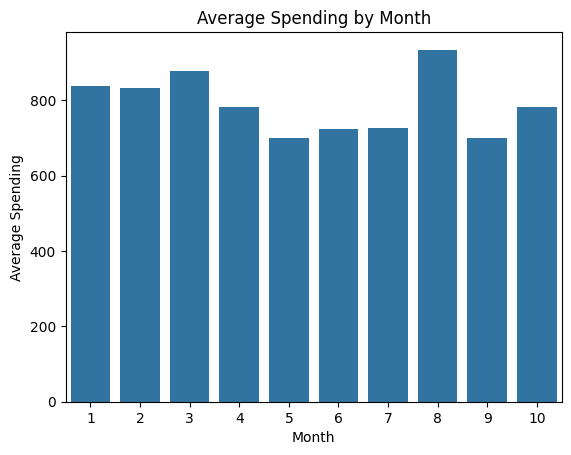

In [16]:
average_spending=df.groupby('month')['amount'].mean()
sns.barplot(x=average_spending.index,y=average_spending.values)
plt.xlabel('Month')
plt.ylabel('Average Spending')
plt.title('Average Spending by Month')
plt.show()

In [17]:
category_spending=df.groupby('category')['amount'].sum()
print(category_spending)

category
entertainment     77530.096535
food              47397.000000
transport         42496.096535
utility          156568.193069
Name: amount, dtype: float64


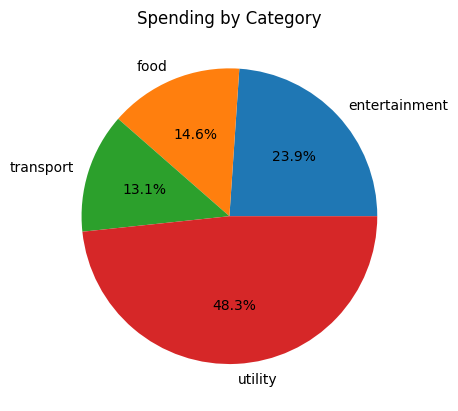

In [18]:
category_spending=df.groupby('category')['amount'].sum()
plt.pie(category_spending,labels=category_spending.index,autopct='%1.1f%%')
plt.title('Spending by Category')
plt.show()

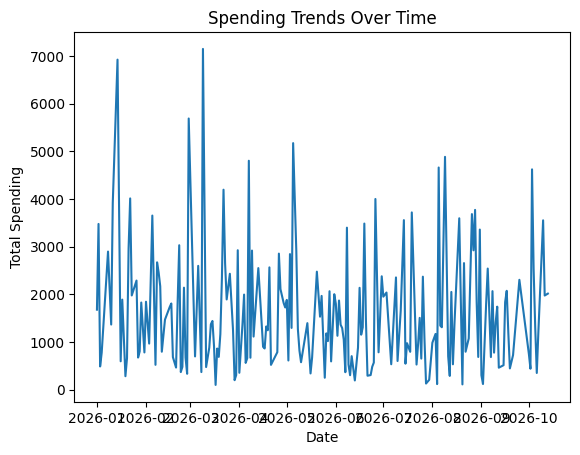

In [19]:
trends_spending=df.groupby('date')['amount'].sum()
plt.plot(trends_spending.index,trends_spending.values)
plt.xlabel('Date')
plt.ylabel('Total Spending')
plt.title('Spending Trends Over Time')
plt.show()

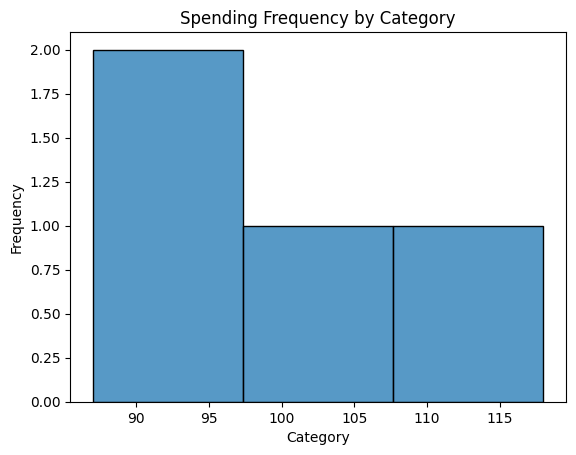

In [20]:
frequency_spending=df['category'].value_counts()
sns.histplot(frequency_spending.values,bins=3)
plt.xlabel('Category')
plt.ylabel('Frequency')
plt.title('Spending Frequency by Category')
plt.show()

ExpenseTracker Class

In [21]:
class ExpenseTracker:
    def __init__(self,df):
        self.df=df

    def add_expense(self,date,amount,category,description):
        if amount<=0:
            print('Amount must be positive')
            return
        if category.strip()=='' or description.strip()=='':
            print('Category and description cannot be empty')
            return
        try:
            date=pd.to_datetime(date)
        except:
            print('Invalid date')
            return
        new_expense={'date':date,'amount':amount,'category':category,'description':description,'month':date.month}
        self.df=pd.concat([self.df,pd.DataFrame([new_expense])],ignore_index=True)
        print('Expense added:',description,'-',amount)

    def get_summary(self):
        total=self.df['amount'].sum()
        average=self.df['amount'].mean()
        highest=self.df['amount'].max()
        lowest=self.df['amount'].min()
        print('Total expenses:',round(total,2))
        print('Average expense:',round(average,2))
        print('Highest expense:',round(highest,2))
        print('Lowest expense:',round(lowest,2))
        return total,average

    def filter_expenses(self,condition):
        result=self.df.copy()
        if 'category' in condition:
            result=result[result['category']==condition['category']]
        if 'start_date' in condition:
            result=result[result['date']>=pd.to_datetime(condition['start_date'])]
        if 'end_date' in condition:
            result=result[result['date']<=pd.to_datetime(condition['end_date'])]
        if 'min_amount' in condition:
            result=result[result['amount']>=condition['min_amount']]
        if 'max_amount' in condition:
            result=result[result['amount']<=condition['max_amount']]
        return result

    def generate_report(self):
        category_total=self.df.groupby('category')['amount'].sum()
        month_total=self.df.groupby('month')['amount'].sum()
        print('------ EXPENSE REPORT ------')
        print('Number of expenses:',len(self.df))
        print('Total spending:',round(self.df['amount'].sum(),2))
        print('Average spending:',round(self.df['amount'].mean(),2))
        print('Top category:',category_total.idxmax(),'-',round(category_total.max(),2))
        print('Lowest category:',category_total.idxmin(),'-',round(category_total.min(),2))
        print('Highest spending month:',month_total.idxmax(),'-',round(month_total.max(),2))
        print('Biggest single expense:')
        print(self.df.loc[self.df['amount'].idxmax(),['date','amount','category','description']])
        print('\nSpending by category:')
        print(category_total)

Creating the tracker object

In [22]:
tracker=ExpenseTracker(df)

 **add_expense**

In [28]:
tracker.add_expense('2025-03-15',550.50,'Food','Dinner with friends')
tracker.add_expense('2025-03-16',-100,'Food','Wrong amount')

Expense added: Dinner with friends - 550.5
Amount must be positive


get_summary

In [29]:
tracker.get_summary()

Total expenses: 324992.39
Average expense: 792.66
Highest expense: 2497.0
Lowest expense: 45.0


(np.float64(324992.38613861386), np.float64(792.6643564356435))

filter_expenses

In [30]:
food=tracker.filter_expenses({'category':'Food'})
food.head()

,date,amount,category,description,month
408,2025-03-15,450.5,Food,Dinner with friends,3
409,2025-03-15,550.5,Food,Dinner with friends,3


In [31]:
date_range=tracker.filter_expenses({'start_date':'2025-01-01','end_date':'2025-03-31'})
date_range.head()

,date,amount,category,description,month
408,2025-03-15,450.5,Food,Dinner with friends,3
409,2025-03-15,550.5,Food,Dinner with friends,3


In [32]:
big_food=tracker.filter_expenses({'category':'Food','min_amount':500})
big_food.head()

,date,amount,category,description,month
409,2025-03-15,550.5,Food,Dinner with friends,3


generate report

In [33]:
tracker.generate_report()

------ EXPENSE REPORT ------
Number of expenses: 410
Total spending: 324992.39
Average spending: 792.66
Top category: utility - 156568.19
Lowest category: Food - 1001.0
Highest spending month: 8 - 43908.1
Biggest single expense:
date           2026-03-06 00:00:00
amount                      2497.0
category                   utility
description               Gas bill
Name: 86, dtype: object

Spending by category:
category
Food               1001.000000
entertainment     77530.096535
food              47397.000000
transport         42496.096535
utility          156568.193069
Name: amount, dtype: float64
